# COU 07506 Digital Signal Processing — Week 2, Lab 1A
## Sampling, Aliasing and Quantization

**Name:** KILIAKI, LAURENT HASSANI  
**Registration number:** 240647412039

AI-use statement: I used AI to help draft explanations and code for this notebook. I reviewed the work and added my own observations.

## Pre-lab

### 1. A 7 kHz tone sampled at 10 kHz

The Nyquist frequency is 5 kHz, so 7 kHz folds into the baseband:

\[f_{alias}=|7-1(10)|=3\;\text{kHz}.\]

The apparent tone is **3 kHz**.

### 2. An 8-bit quantizer with a ±1 V range

There are $2^8=256$ levels, so the quantization step is

\[
\Delta=\frac{V_{\max}-V_{\min}}{2^n}
\]

For a full-scale sine wave, the theoretical SQNR is $6.02(8)+1.76=\mathbf{49.92\;dB}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
from pathlib import Path

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

## Task 2.1 — Aliasing of a sinusoid

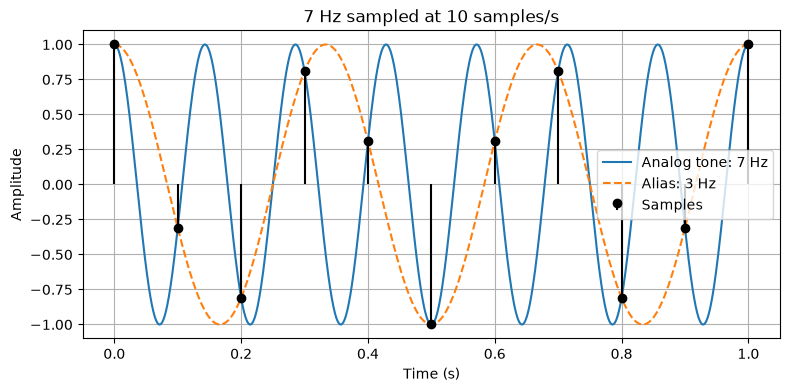

Input tone = 7 Hz
fs (Hz) | predicted alias (Hz)
   10.0 |                   3.0
   12.0 |                   5.0
   14.0 |                   7.0
   20.0 |                   7.0


In [2]:
def alias_frequency(f0, fs):
    """Fold a nonnegative tone into the Nyquist interval [0, fs/2]."""
    return abs(((f0 + fs/2) % fs) - fs/2)

f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000, endpoint=True)
n = np.arange(0, int(fs) + 1)
tn = n / fs
f_alias = alias_frequency(f0, fs)

plt.plot(t, np.cos(2*np.pi*f0*t), label=f"Analog tone: {f0:g} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"Alias: {f_alias:g} Hz")
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ", label="Samples")
plt.xlabel("Time (s)"); plt.ylabel("Amplitude"); plt.title("7 Hz sampled at 10 samples/s")
plt.legend(); plt.show()

# Repeat the manual's request for fs = 12, 14, and 20 Hz.
rows = []
for fs_i in [10, 12, 14, 20]:
    rows.append((fs_i, alias_frequency(f0, fs_i)))
print("Input tone = 7 Hz")
print("fs (Hz) | predicted alias (Hz)")
for fs_i, fa in rows:
    print(f"{fs_i:7.1f} | {fa:21.1f}")


### Results

For a 7 Hz tone, the predicted aliases are 3 Hz at $f_s=10$ Hz, 5 Hz at 12 Hz, and 7 Hz at both 14 Hz and 20 Hz. At 14 Hz, the tone is exactly at Nyquist; at 20 Hz, it is below Nyquist and is sampled without aliasing.

## Task 2.2 — Hear aliasing